# 04 — State Characterization and Task Relationships

Notebook 03 fitted the TDE-HMM and saved the state dictionary plus
per-subject state time courses. This notebook does two things:

1. **Characterize** the discovered states in sensor space — their
   spectral profiles and their spatial topographies.
2. **Relate** state dynamics to the experimental variables: task phase,
   cognitive load, response accuracy, and reaction time.

**Methodological discipline.** The state dictionary was frozen in
notebook 03 without any access to labels. Labels are revealed for the
first time here. Any relationship we report between state dynamics and
task variables is therefore *discovered*, not imposed.

**Sensor-space interpretation.** EEG topographies reflect scalp
potential distributions. A state with a frontocentral scalp pattern is
consistent with activity over frontal and central regions, but this does
not by itself establish a cortical network or generator without source
localization.

**Reference method.** State characterization follows Quinn et al. (2018,
*Front. Neurosci.*): evoked fractional occupancy, aligned across trials,
analyzed against baseline. State-resolved spectral characterization
follows the OHBA TDE-HMM literature (Vidaurre et al. 2016, *NeuroImage*;
osl-dynamics toolbox).

In [9]:
# Setup for notebook 04.
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC = REPO_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from scipy import stats
import pickle
with open(config.RESULTS / "models" / "tde_hmm_model.pkl", "rb") as f:
    artifacts = pickle.load(f)

from eeg_state import config, model
from eeg_state.io import load_events, reconstruct_trials
from eeg_state.io import (
    ENCODING_DURATION, RETENTION_DURATION,
    RETRIEVAL_ONSET_OFFSET, RETRIEVAL_DURATION,
)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

TRIAL_DURATION_S = 5.0
TDE_TRIM = abs(artifacts["tde_lags"][0])
FS = artifacts["target_sfreq"]

RARE_STATE = int(np.argmax(np.linalg.norm(artifacts["hmm"].means_, axis=1)))
DOMINANT_STATE = 1 - RARE_STATE

# Load the frozen model artifacts from notebook 03.
with open(config.RESULTS / "models" / "tde_hmm_model.pkl", "rb") as f:
    artifacts = pickle.load(f)

K = artifacts["n_states"]
print(f"Loaded model: K={K}, N_PCS={artifacts['n_pcs']}, "
      f"tde lags={artifacts['tde_lags'][0]}..{artifacts['tde_lags'][-1]}")
print(f"Development subjects: {artifacts['dev_subjects']}")


def iterate_trials(subject, artifacts):
    """Yield (eeg_segment, posteriors) for each valid trial.

    Two distinct indices: `sample_cursor` tracks position in the concatenated
    posteriors array; `length_idx` tracks position in the lengths array.
    Trial skip logic mirrors extract_trials so alignment is preserved.
    """
    fs = artifacts["target_sfreq"]
    trim = abs(artifacts["tde_lags"][0])
    n_samples = int(TRIAL_DURATION_S * fs)

    raw = mne.io.read_raw_fif(
        config.DATA_DERIV / subject / f"{subject}_preprocessed_raw.fif",
        preload=True, verbose="ERROR",
    )
    data = raw.get_data() * 1e6
    trials_df = reconstruct_trials(load_events(subject))
    npz = np.load(config.DATA_DERIV / subject / f"{subject}_states.npz")
    posteriors = npz["posteriors"]
    lengths = npz["lengths"]

    sample_cursor = 0
    length_idx = 0
    for _, t in trials_df.iterrows():
        start = int(t["encoding_onset_s"] * fs)
        end = start + n_samples
        if end > data.shape[1]:
            continue
        L = int(lengths[length_idx])
        eeg = data[:, start + trim : start + trim + L]
        post = posteriors[sample_cursor : sample_cursor + L]
        sample_cursor += L
        length_idx += 1
        yield eeg, post


print("Helpers ready.")

Loaded model: K=2, N_PCS=20, tde lags=-25..25
Development subjects: ['sub-04', 'sub-05', 'sub-10', 'sub-11', 'sub-17', 'sub-24', 'sub-34', 'sub-45']
Helpers ready.


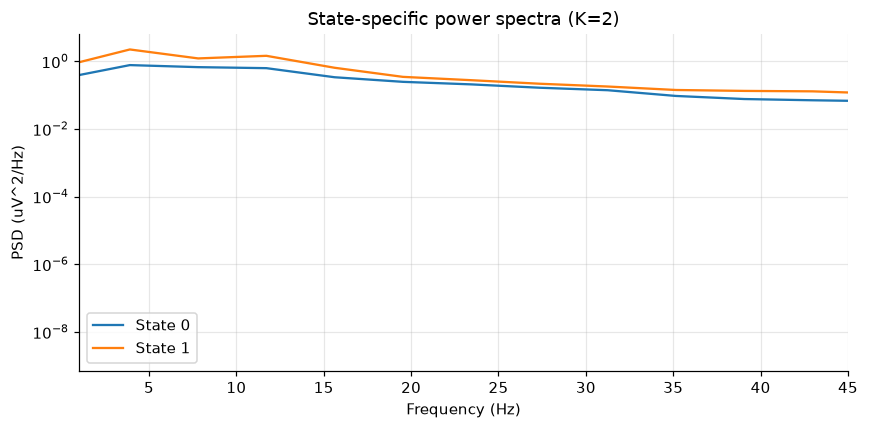

        state 0   state 1
delta  0.770185  2.232803
theta   0.66979  1.213708
alpha  0.625311  1.448932
beta   0.218957  0.331797
gamma  0.080329   0.13446


In [21]:
# Compute per-state PSD using windowed FFT weighted by state posteriors.
# Window length 64 samples (256 ms) balances spectral resolution against
# state dwell time. Soft (posterior) weighting lets windows with mixed
# states contribute proportionally.

def compute_state_spectra(subjects, artifacts, win_len=64, hop=32):
    fs = artifacts["target_sfreq"]
    K = artifacts["n_states"]
    psd_sum, weight_sum = None, None
    f = None

    for sub in subjects:
        for eeg, post in iterate_trials(sub, artifacts):
            L = eeg.shape[1]
            for w in range(0, L - win_len + 1, hop):
                seg = eeg[:, w : w + win_len]
                wp = post[w : w + win_len].mean(axis=0)
                seg = seg - seg.mean(axis=1, keepdims=True)
                taper = np.hanning(win_len)
                fft = np.fft.rfft(seg * taper, axis=1)
                pxx = (np.abs(fft) ** 2) * 2 / (fs * np.sum(taper ** 2))

                if psd_sum is None:
                    f = np.fft.rfftfreq(win_len, d=1.0 / fs)
                    psd_sum = np.zeros((K, pxx.shape[0], len(f)))
                    weight_sum = np.zeros(K)
                for k in range(K):
                    psd_sum[k] += wp[k] * pxx
                    weight_sum[k] += wp[k]

    return f, psd_sum / np.maximum(weight_sum[:, None, None], 1e-10)


f, psd = compute_state_spectra(config.DEV_SUBJECTS, artifacts)

fig, ax = plt.subplots(figsize=(8, 4))
for k in range(K):
    p = psd[k].mean(axis=0)  # channel-averaged
    ax.semilogy(f, p, label=f"State {k}", linewidth=1.5)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("PSD (uV^2/Hz)")
ax.set_xlim(1, 45)
ax.set_title(f"State-specific power spectra (K={K})")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# Print band-power ratios for the key bands, useful for the markdown.
bands = {
    "delta": (0.1, 4.0),      # bin 3.906
    "theta": (4.0, 8.0),      # bin 7.812
    "alpha": (8.0, 12.0),     # bin 11.719
    "beta":  (12.0, 32.0),    # bins 15.625, 19.531, 23.438, 27.344, 31.25
    "gamma": (32.0, 45.0),    # bins 35.156, 39.062, 42.969
}
df = pd.DataFrame(index=list(bands.keys()), columns=[f"state {k}" for k in range(K)])
for name, (lo, hi) in bands.items():
    mask = (f >= lo - 1e-6) & (f <= hi + 1e-6)
    for k in range(K):
        df.loc[name, f"state {k}"] = psd[k][:, mask].mean()
print(df.round(4))

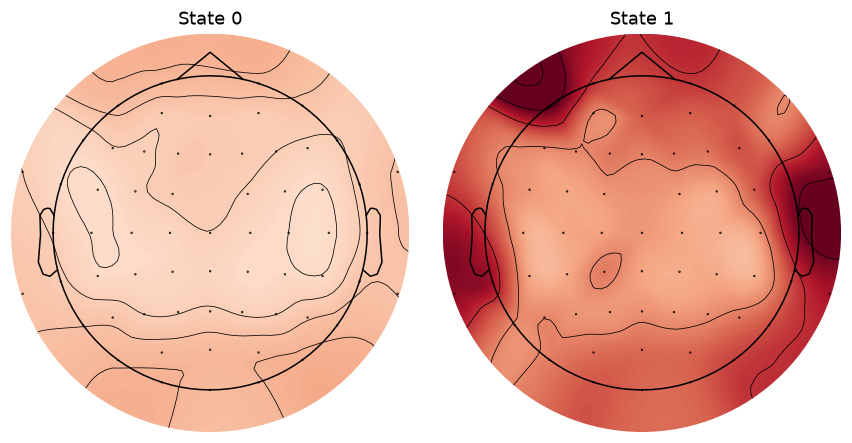

State 0 top-5 channels: [('PO8', 5.836), ('O1', 5.73), ('O2', 5.556), ('PO7', 5.469), ('PO4', 5.444)]
State 1 top-5 channels: [('AF7', 16.522), ('FT10', 15.509), ('T8', 15.325), ('FT8', 14.853), ('TP9', 14.747)]


In [16]:
# Per-state scalp power map, averaged across subjects.
# For each state, select the samples assigned to that state (hard Viterbi
# assignment) and compute the RMS amplitude per channel.

def compute_state_topography(subjects, artifacts):
    K = artifacts["n_states"]
    topo_sum = np.zeros((K, 63))
    n_subj = 0

    for sub in subjects:
        npz = np.load(config.DATA_DERIV / sub / f"{sub}_states.npz")
        viterbi = npz["viterbi"]
        fs = artifacts["target_sfreq"]
        trim = abs(artifacts["tde_lags"][0])
        n_samples = int(TRIAL_DURATION_S * fs)

        raw = mne.io.read_raw_fif(
            config.DATA_DERIV / sub / f"{sub}_preprocessed_raw.fif",
            preload=True, verbose="ERROR")
        data = raw.get_data() * 1e6
        trials_df = reconstruct_trials(load_events(sub))
        lengths = npz["lengths"]

        sub_sq = np.zeros((K, 63))
        sub_n = np.zeros(K)
        sample_cursor = 0
        length_idx = 0
        for _, t in trials_df.iterrows():
            start = int(t["encoding_onset_s"] * fs)
            if start + n_samples > data.shape[1]:
                continue
            L = int(lengths[length_idx])
            eeg = data[:, start + trim : start + trim + L]
            seg_v = viterbi[sample_cursor : sample_cursor + L]
            sample_cursor += L
            length_idx += 1
            for k in range(K):
                m = seg_v == k
                if m.any():
                    sub_sq[k] += np.sum(eeg[:, m] ** 2, axis=1)
                    sub_n[k] += m.sum()

        for k in range(K):
            if sub_n[k] > 0:
                topo_sum[k] += np.sqrt(sub_sq[k] / sub_n[k])
        n_subj += 1

    return topo_sum / n_subj


topo = compute_state_topography(config.DEV_SUBJECTS, artifacts)

# Reuse the info from a preprocessed file for the montage.
raw0 = mne.io.read_raw_fif(
    config.DATA_DERIV / config.DEV_SUBJECTS[0]
    / f"{config.DEV_SUBJECTS[0]}_preprocessed_raw.fif",
    preload=False, verbose="ERROR")

fig, axes = plt.subplots(1, K, figsize=(4 * K, 4))
if K == 1:
    axes = [axes]
vmax = np.abs(topo).max()
for k, ax in enumerate(axes):
    im, _ = mne.viz.plot_topomap(
        topo[k], raw0.info, axes=ax, show=False,
        cmap="RdBu_r", vlim=(-vmax, vmax), contours=4,
    )
    ax.set_title(f"State {k}")
plt.tight_layout()
plt.show()

# Quantify: which channels are strongest in each state?
ch_names = raw0.ch_names
for k in range(K):
    idx = np.argsort(np.abs(topo[k]))[::-1][:5]
    print(f"State {k} top-5 channels: "
          f"{[(ch_names[i], round(float(topo[k][i]), 3)) for i in idx]}")

In [36]:
# Spatial correlation between state topographies.
r = np.corrcoef(topo[0], topo[1])[0, 1]
print(f"Spatial correlation between state 0 and state 1 topographies: {r:.3f}")
print(f"Amplitude ratio (max channel): "
      f"{np.abs(topo[1]).max() / np.abs(topo[0]).max():.2f}")

Spatial correlation between state 0 and state 1 topographies: 0.535
Amplitude ratio (max channel): 2.83


In [37]:
print("State means in PCA space (20 PCs):")
print(artifacts["hmm"].means_.round(3))
print("\nComponent-wise difference (state 1 - state 0):")
print((artifacts["hmm"].means_[1] - artifacts["hmm"].means_[0]).round(3))
print("\nCovariance traces:")
for k in range(2):
    print(f"  state {k}: trace = {np.trace(artifacts['hmm'].covars_[k]):.3f}")

State means in PCA space (20 PCs):
[[ 0.001 -0.004  0.005 -0.001  0.002  0.003  0.    -0.    -0.002 -0.002
   0.011 -0.     0.003  0.01  -0.006  0.003 -0.005 -0.001  0.001 -0.001]
 [-0.008  0.06  -0.065  0.014 -0.024 -0.04  -0.002  0.     0.034  0.033
  -0.15   0.002 -0.042 -0.144  0.083 -0.042  0.069  0.01  -0.009  0.018]]

Component-wise difference (state 1 - state 0):
[-0.009  0.064 -0.069  0.015 -0.026 -0.043 -0.003  0.     0.036  0.035
 -0.161  0.002 -0.045 -0.154  0.089 -0.045  0.074  0.01  -0.01   0.019]

Covariance traces:
  state 0: trace = 15.681
  state 1: trace = 79.368


In [38]:
# Is state 1 really "more autocorrelated but not more oscillatory"?
print("State 1 cov trace / state 0 cov trace:",
      np.trace(artifacts["hmm"].covars_[1]) / np.trace(artifacts["hmm"].covars_[0]))
print("State 1 mean norm / state 0 mean norm:",
      np.linalg.norm(artifacts["hmm"].means_[1]) / np.linalg.norm(artifacts["hmm"].means_[0]))

State 1 cov trace / state 0 cov trace: 5.061301842095099
State 1 mean norm / state 0 mean norm: 13.764543014747751


In [ ]:
from eeg_state.io import (
    ENCODING_DURATION, RETENTION_DURATION,
    RETRIEVAL_ONSET_OFFSET, RETRIEVAL_DURATION,
)

TRIAL_DURATION_S = 5.0
TDE_TRIM = abs(artifacts["tde_lags"][0])   # 25 samples
FS = artifacts["target_sfreq"]              # 250 Hz

RARE_STATE = int(np.argmax(np.linalg.norm(artifacts["hmm"].means_, axis=1)))
DOMINANT_STATE = 1 - RARE_STATE
print(f"Rare state index = {RARE_STATE} (occupancy ~6-7%)")
print(f"Dominant state index = {DOMINANT_STATE} (occupancy ~93%)")

Rare state index = 1 (occupancy ~6-7%)
Dominant state index = 0 (occupancy ~93%)


In [40]:
def load_trial_posteriors(subject, artifacts):
    npz = np.load(config.DATA_DERIV / subject / f"{subject}_states.npz")
    post = npz["posteriors"]
    lengths = npz["lengths"]

    raw = mne.io.read_raw_fif(
        config.DATA_DERIV / subject / f"{subject}_preprocessed_raw.fif",
        preload=False, verbose="ERROR",
    )
    n_samples_raw = raw.n_times
    trials_df = reconstruct_trials(load_events(subject))

    trim = abs(artifacts["tde_lags"][0])
    n_trial_samples = int(TRIAL_DURATION_S * artifacts["target_sfreq"])
    sfreq = artifacts["target_sfreq"]

    records = []
    sample_cursor = 0
    length_idx = 0
    for _, row in trials_df.iterrows():
        start = int(row["encoding_onset_s"] * sfreq)
        end = start + n_trial_samples
        if end > n_samples_raw:
            continue
        L = int(lengths[length_idx])
        post_trial = post[sample_cursor : sample_cursor + L]
        sample_cursor += L
        length_idx += 1

        t_rel = (np.arange(L) + trim) / sfreq
        records.append({
            "subject": subject,
            "trial_idx": int(row["trial_idx"]),
            "load": int(row["load"]),
            "probe_present": bool(row["probe_present"]),
            "correct": row["correct"],
            "rt_s": row["rt_s"],
            "posteriors": post_trial,
            "t_rel": t_rel,
        })

    assert length_idx == len(lengths), (
        f"{subject}: length mismatch ({length_idx} vs {len(lengths)})"
    )
    assert sample_cursor == post.shape[0], (
        f"{subject}: sample mismatch ({sample_cursor} vs {post.shape[0]})"
    )
    return records

print("Loading per-trial posteriors ...")
all_trials = []
for sub in config.DEV_SUBJECTS:
    recs = load_trial_posteriors(sub, artifacts)
    all_trials.extend(recs)
    print(f"  {sub}: {len(recs)} trials")

print(f"\nTotal: {len(all_trials)} trials across {len(config.DEV_SUBJECTS)} subjects")

Loading per-trial posteriors ...
  sub-04: 197 trials
  sub-05: 200 trials
  sub-10: 200 trials
  sub-11: 200 trials
  sub-17: 200 trials
  sub-24: 200 trials
  sub-34: 200 trials
  sub-45: 200 trials

Total: 1597 trials across 8 subjects


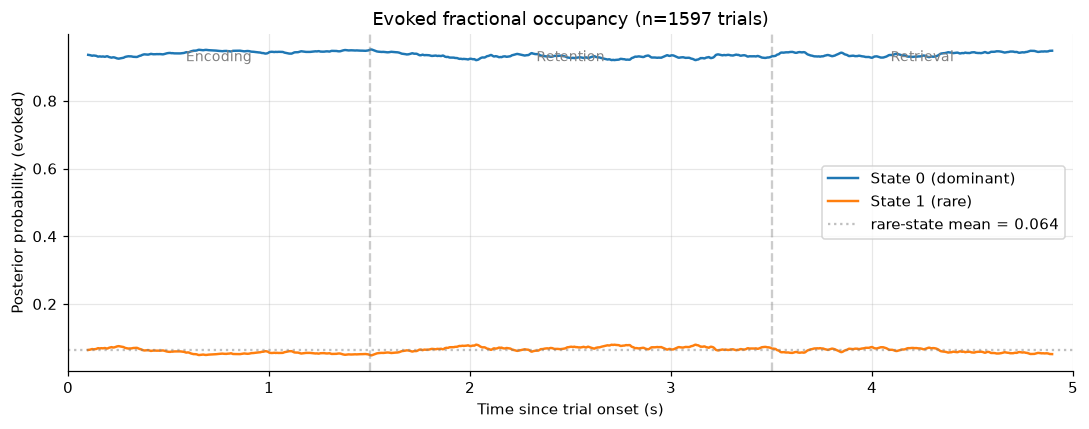

In [41]:
L_max = max(len(r["posteriors"]) for r in all_trials)
t_common = (np.arange(L_max) + TDE_TRIM) / FS   # 0.1 .. 4.9 s

post_sum = np.zeros((L_max, artifacts["n_states"]))
count = np.zeros(L_max)
for r in all_trials:
    L = len(r["posteriors"])
    post_sum[:L] += r["posteriors"]
    count[:L] += 1
evoked = post_sum / np.maximum(count[:, None], 1)

fig, ax = plt.subplots(figsize=(10, 4))
for k in range(artifacts["n_states"]):
    label = f"State {k}" + (" (rare)" if k == RARE_STATE else " (dominant)")
    ax.plot(t_common, evoked[:, k], label=label, linewidth=1.6)

rare_mean = evoked[:, RARE_STATE].mean()
ax.axhline(rare_mean, color="gray", linestyle=":", alpha=0.5,
           label=f"rare-state mean = {rare_mean:.3f}")

for x in (ENCODING_DURATION, RETRIEVAL_ONSET_OFFSET):
    ax.axvline(x, color="gray", linestyle="--", alpha=0.4)
ymax = ax.get_ylim()[1]
ax.text(0.75, ymax * 0.92, "Encoding", ha="center", fontsize=9, color="gray")
ax.text(2.5, ymax * 0.92, "Retention", ha="center", fontsize=9, color="gray")
ax.text(4.25, ymax * 0.92, "Retrieval", ha="center", fontsize=9, color="gray")

ax.set_xlabel("Time since trial onset (s)")
ax.set_ylabel("Posterior probability (evoked)")
ax.set_title(f"Evoked fractional occupancy (n={len(all_trials)} trials)")
ax.set_xlim(0, TRIAL_DURATION_S)
ax.legend(loc="center right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

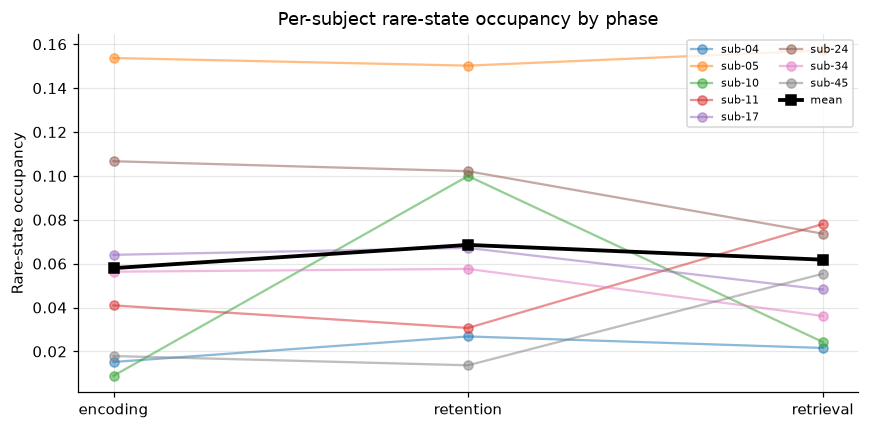

Friedman across phases: chi2 = 0.250,  p = 0.8825

phase    encoding  retention  retrieval
subject                                
sub-04      0.015      0.027      0.022
sub-05      0.154      0.150      0.157
sub-10      0.009      0.100      0.024
sub-11      0.041      0.031      0.078
sub-17      0.064      0.067      0.048
sub-24      0.107      0.102      0.074
sub-34      0.056      0.058      0.036
sub-45      0.018      0.014      0.055


In [42]:
def phase_means(t_rel, posteriors):
    """Mean posterior per state in encoding, retention, retrieval."""
    masks = {
        "encoding":  (t_rel >= 0) & (t_rel < ENCODING_DURATION),
        "retention": (t_rel >= ENCODING_DURATION) & (t_rel < RETRIEVAL_ONSET_OFFSET),
        "retrieval": (t_rel >= RETRIEVAL_ONSET_OFFSET) & (t_rel < TRIAL_DURATION_S),
    }
    return {name: posteriors[m].mean(axis=0) for name, m in masks.items()}


phase_rows = []
for r in all_trials:
    for phase, p in phase_means(r["t_rel"], r["posteriors"]).items():
        phase_rows.append({
            "subject": r["subject"],
            "trial_idx": r["trial_idx"],
            "phase": phase,
            "occ_rare": p[RARE_STATE],
        })
phase_df = pd.DataFrame(phase_rows)

subj_phase = phase_df.groupby(["subject", "phase"])["occ_rare"].mean().unstack()
phases = ["encoding", "retention", "retrieval"]

fig, ax = plt.subplots(figsize=(8, 4))
for sub in subj_phase.index:
    ax.plot(phases, subj_phase.loc[sub, phases].values,
            marker="o", alpha=0.5, label=sub)
ax.plot(phases, subj_phase[phases].mean().values,
        marker="s", linewidth=2.5, color="black", label="mean")
ax.set_ylabel("Rare-state occupancy")
ax.set_title("Per-subject rare-state occupancy by phase")
ax.legend(fontsize=7, ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

stat, p = stats.friedmanchisquare(*[subj_phase[ph].values for ph in phases])
print(f"Friedman across phases: chi2 = {stat:.3f},  p = {p:.4f}")
print()
print(subj_phase.round(3))

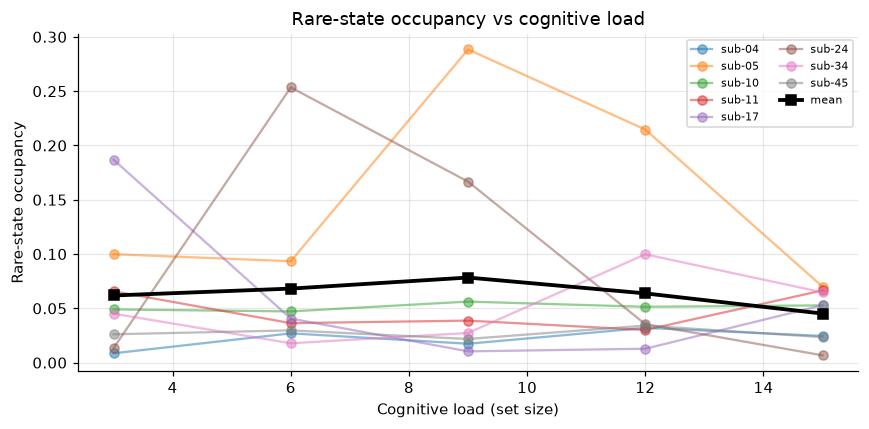

Friedman across loads: chi2 = 1.100,  p = 0.8943

load        3      6      9      12     15
subject                                   
sub-04   0.009  0.027  0.017  0.032  0.025
sub-05   0.100  0.093  0.288  0.215  0.070
sub-10   0.049  0.047  0.056  0.051  0.053
sub-11   0.066  0.036  0.039  0.030  0.067
sub-17   0.187  0.041  0.010  0.013  0.053
sub-24   0.013  0.254  0.167  0.035  0.007
sub-34   0.045  0.018  0.027  0.100  0.065
sub-45   0.026  0.030  0.022  0.034  0.024


In [43]:
load_rows = []
for r in all_trials:
    load_rows.append({
        "subject": r["subject"],
        "load": r["load"],
        "occ_rare": r["posteriors"][:, RARE_STATE].mean(),
    })
load_df = pd.DataFrame(load_rows)

subj_load = load_df.groupby(["subject", "load"])["occ_rare"].mean().unstack()
# Drop any load column with NaN (subject missing that set size)
subj_load_clean = subj_load.dropna(axis=1)
loads = sorted(subj_load_clean.columns)

fig, ax = plt.subplots(figsize=(8, 4))
for sub in subj_load_clean.index:
    ax.plot(loads, subj_load_clean.loc[sub, loads].values,
            marker="o", alpha=0.5, label=sub)
ax.plot(loads, subj_load_clean[loads].mean().values,
        marker="s", linewidth=2.5, color="black", label="mean")
ax.set_xlabel("Cognitive load (set size)")
ax.set_ylabel("Rare-state occupancy")
ax.set_title("Rare-state occupancy vs cognitive load")
ax.legend(fontsize=7, ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

stat, p = stats.friedmanchisquare(*[subj_load_clean[l].values for l in loads])
print(f"Friedman across loads: chi2 = {stat:.3f},  p = {p:.4f}")
print()
print(subj_load_clean.round(3))

        occ_rare  accuracy  rt_median
sub-04     0.022     0.807      1.058
sub-05     0.153     0.770      0.758
sub-10     0.051     0.815      0.745
sub-11     0.047     0.835      0.917
sub-17     0.061     0.760      0.792
sub-24     0.095     0.750      0.972
sub-34     0.051     0.870      1.058
sub-45     0.027     0.830      1.071


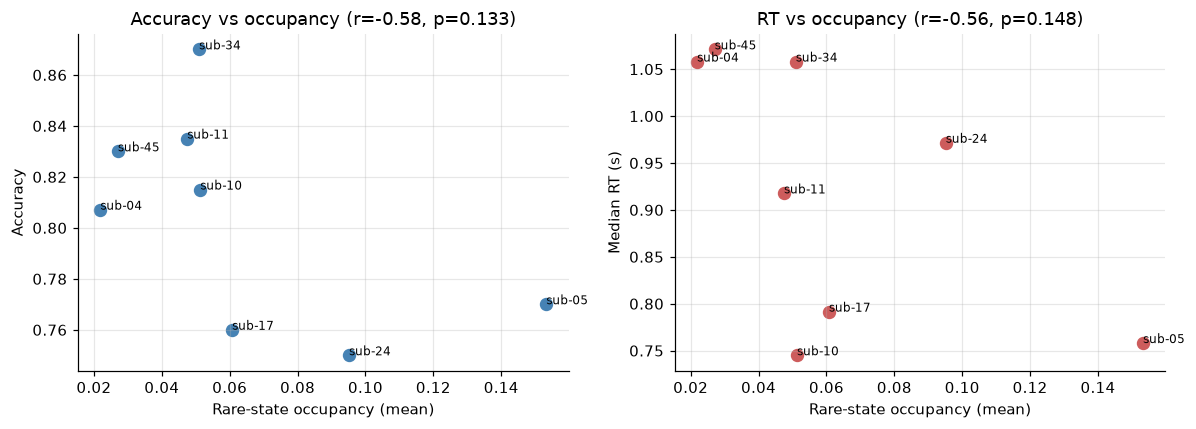

In [44]:
# Per-subject rare-state occupancy
occ_by_subj = load_df.groupby("subject")["occ_rare"].mean()

# Per-subject accuracy and median RT (from event reconstruction)
acc_by_subj, rt_by_subj = {}, {}
for sub in config.DEV_SUBJECTS:
    trials = reconstruct_trials(load_events(sub))
    acc_by_subj[sub] = trials["correct"].mean()      # NaN-skipped
    rt_by_subj[sub]  = trials["rt_s"].median()

behavioral = pd.DataFrame({
    "occ_rare":  occ_by_subj,
    "accuracy":  pd.Series(acc_by_subj),
    "rt_median": pd.Series(rt_by_subj),
})
print(behavioral.round(3))

r_acc, p_acc = stats.pearsonr(behavioral["occ_rare"], behavioral["accuracy"])
r_rt,  p_rt  = stats.pearsonr(behavioral["occ_rare"], behavioral["rt_median"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(behavioral["occ_rare"], behavioral["accuracy"],
                color="steelblue", s=60)
for sub, row in behavioral.iterrows():
    axes[0].annotate(sub, (row["occ_rare"], row["accuracy"]), fontsize=8)
axes[0].set_xlabel("Rare-state occupancy (mean)")
axes[0].set_ylabel("Accuracy")
axes[0].set_title(f"Accuracy vs occupancy (r={r_acc:.2f}, p={p_acc:.3f})")
axes[0].grid(alpha=0.3)

axes[1].scatter(behavioral["occ_rare"], behavioral["rt_median"],
                color="indianred", s=60)
for sub, row in behavioral.iterrows():
    axes[1].annotate(sub, (row["occ_rare"], row["rt_median"]), fontsize=8)
axes[1].set_xlabel("Rare-state occupancy (mean)")
axes[1].set_ylabel("Median RT (s)")
axes[1].set_title(f"RT vs occupancy (r={r_rt:.2f}, p={p_rt:.3f})")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [5]:
def load_trial_data(subject, artifacts):
    """Load viterbi + posteriors + trial metadata with fixed cursor logic.
    Same trial-skip logic as extract_trials so alignment is preserved."""
    npz = np.load(config.DATA_DERIV / subject / f"{subject}_states.npz")
    vit = npz["viterbi"]
    post = npz["posteriors"]
    lengths = npz["lengths"]

    raw = mne.io.read_raw_fif(
        config.DATA_DERIV / subject / f"{subject}_preprocessed_raw.fif",
        preload=False, verbose="ERROR",
    )
    n_samples_raw = raw.n_times
    trials_df = reconstruct_trials(load_events(subject))

    trim = abs(artifacts["tde_lags"][0])
    n_trial_samples = int(TRIAL_DURATION_S * artifacts["target_sfreq"])
    sfreq = artifacts["target_sfreq"]

    records = []
    sample_cursor = 0
    length_idx = 0
    for _, row in trials_df.iterrows():
        start = int(row["encoding_onset_s"] * sfreq)
        end = start + n_trial_samples
        if end > n_samples_raw:
            continue
        L = int(lengths[length_idx])
        records.append({
            "subject": subject,
            "trial_idx": int(row["trial_idx"]),
            "load": int(row["load"]),
            "correct": row["correct"],
            "rt_s": row["rt_s"],
            "viterbi": vit[sample_cursor:sample_cursor+L],
            "posteriors": post[sample_cursor:sample_cursor+L],
            "t_rel": (np.arange(L) + trim) / sfreq,
        })
        sample_cursor += L
        length_idx += 1

    assert length_idx == len(lengths)
    assert sample_cursor == vit.shape[0]
    return records


def phase_of(t_s):
    if t_s < ENCODING_DURATION:
        return "encoding"
    if t_s < RETRIEVAL_ONSET_OFFSET:
        return "retention"
    return "retrieval"


phases = ["encoding", "retention", "retrieval"]

print("Loading trial data with viterbi ...")
all_trial_data = []
for sub in config.DEV_SUBJECTS:
    recs = load_trial_data(sub, artifacts)
    all_trial_data.extend(recs)
    print(f"  {sub}: {len(recs)} trials")
print(f"\nTotal: {len(all_trial_data)} trials")

Loading trial data with viterbi ...
  sub-04: 197 trials
  sub-05: 200 trials
  sub-10: 200 trials
  sub-11: 200 trials
  sub-17: 200 trials
  sub-24: 200 trials
  sub-34: 200 trials
  sub-45: 200 trials

Total: 1597 trials


Total rare-state visits: 1834
Median dwell across all: 112.0 ms
Mean dwell across all:   264.3 ms



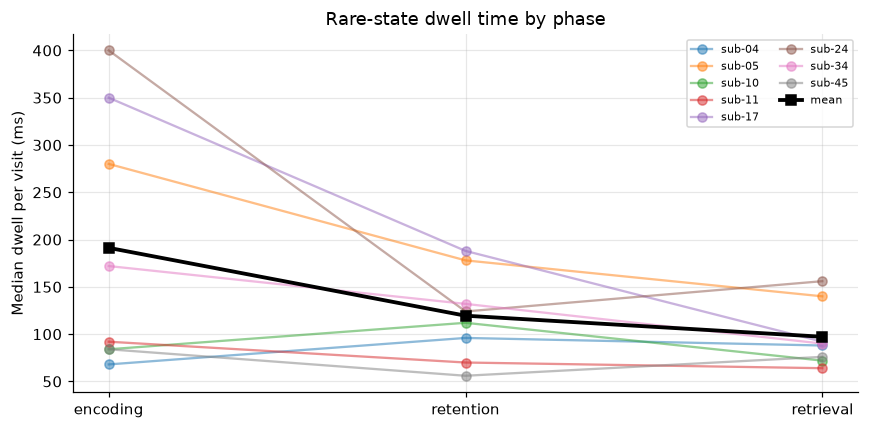

Friedman dwell across phases: chi2=6.250, p=0.0439

phase    encoding  retention  retrieval
subject                                
sub-04       68.0       96.0       88.0
sub-05      280.0      178.0      140.0
sub-10       84.0      112.0       72.0
sub-11       92.0       70.0       64.0
sub-17      350.0      188.0       92.0
sub-24      400.0      124.0      156.0
sub-34      172.0      132.0       90.0
sub-45       84.0       56.0       76.0



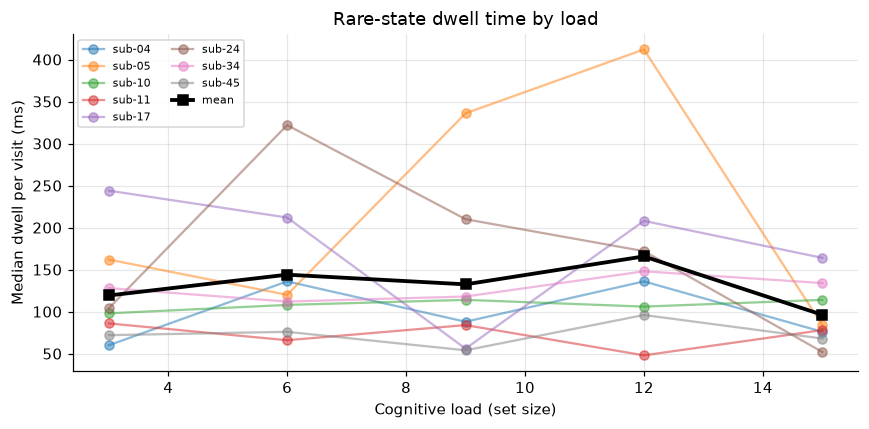

Friedman dwell across loads: chi2=2.228, p=0.6939

load        3      6      9      12     15
subject                                   
sub-04    60.0  136.0   88.0  136.0   76.0
sub-05   162.0  120.0  336.0  412.0   84.0
sub-10    98.0  108.0  114.0  106.0  114.0
sub-11    86.0   66.0   84.0   48.0   78.0
sub-17   244.0  212.0   56.0  208.0  164.0
sub-24   104.0  322.0  210.0  172.0   52.0
sub-34   128.0  112.0  118.0  148.0  134.0
sub-45    72.0   76.0   54.0   96.0   68.0


In [10]:
visits = []
for r in all_trial_data:
    v = r["viterbi"]
    if len(v) == 0:
        continue
    changes = np.where(np.diff(v) != 0)[0] + 1
    boundaries = np.concatenate([[0], changes, [len(v)]])
    for a, b in zip(boundaries[:-1], boundaries[1:]):
        if v[a] == RARE_STATE:
            visits.append({
                "subject": r["subject"],
                "load": r["load"],
                "phase": phase_of(r["t_rel"][a]),
                "dur_ms": (b - a) / FS * 1000,
            })
visits_df = pd.DataFrame(visits)
print(f"Total rare-state visits: {len(visits_df)}")
print(f"Median dwell across all: {visits_df['dur_ms'].median():.1f} ms")
print(f"Mean dwell across all:   {visits_df['dur_ms'].mean():.1f} ms\n")

# --- Dwell by phase ---
subj_dwell_phase = visits_df.groupby(["subject", "phase"])["dur_ms"].median().unstack()

fig, ax = plt.subplots(figsize=(8, 4))
for sub in subj_dwell_phase.index:
    ax.plot(phases, subj_dwell_phase.loc[sub, phases].values,
            marker="o", alpha=0.5, label=sub)
ax.plot(phases, subj_dwell_phase[phases].mean().values,
        marker="s", linewidth=2.5, color="black", label="mean")
ax.set_ylabel("Median dwell per visit (ms)")
ax.set_title("Rare-state dwell time by phase")
ax.legend(fontsize=7, ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

stat, p = stats.friedmanchisquare(*[subj_dwell_phase[ph].values for ph in phases])
print(f"Friedman dwell across phases: chi2={stat:.3f}, p={p:.4f}\n")
print(subj_dwell_phase.round(1).to_string())
print()

# --- Dwell by load ---
subj_dwell_load = (visits_df.groupby(["subject", "load"])["dur_ms"]
                   .median().unstack().dropna(axis=1))
loads = sorted(subj_dwell_load.columns)

fig, ax = plt.subplots(figsize=(8, 4))
for sub in subj_dwell_load.index:
    ax.plot(loads, subj_dwell_load.loc[sub, loads].values,
            marker="o", alpha=0.5, label=sub)
ax.plot(loads, subj_dwell_load[loads].mean().values,
        marker="s", linewidth=2.5, color="black", label="mean")
ax.set_xlabel("Cognitive load (set size)")
ax.set_ylabel("Median dwell per visit (ms)")
ax.set_title("Rare-state dwell time by load")
ax.legend(fontsize=7, ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

stat, p = stats.friedmanchisquare(*[subj_dwell_load[l].values for l in loads])
print(f"Friedman dwell across loads: chi2={stat:.3f}, p={p:.4f}\n")
print(subj_dwell_load.round(1).to_string())

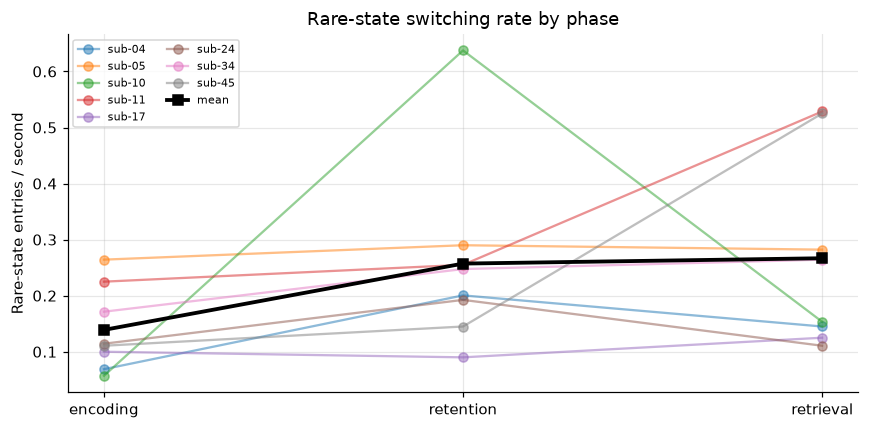

Friedman switching rate across phases: chi2=6.750, p=0.0342

         encoding  retention  retrieval
subject                                
sub-04      0.069      0.201      0.145
sub-05      0.264      0.290      0.282
sub-10      0.057      0.638      0.154
sub-11      0.225      0.255      0.529
sub-17      0.100      0.090      0.125
sub-24      0.114      0.192      0.111
sub-34      0.171      0.248      0.264
sub-45      0.111      0.145      0.525



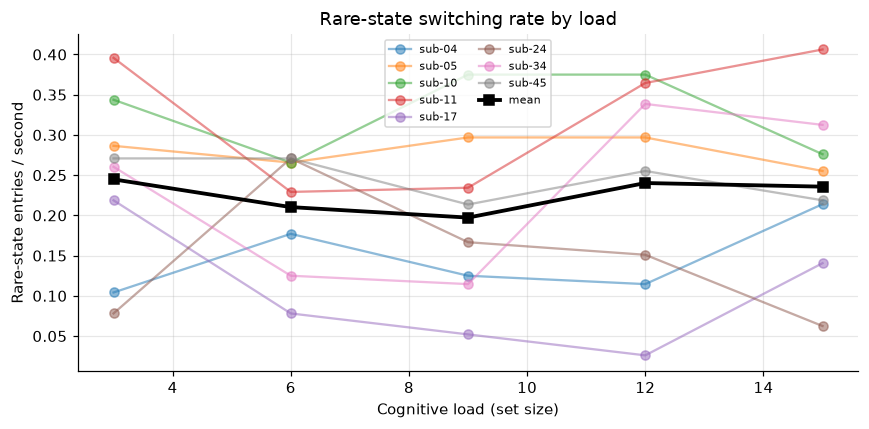

Friedman switching rate across loads: chi2=0.637, p=0.9589

load        3      6      9      12     15
subject                                   
sub-04   0.104  0.177  0.125  0.115  0.214
sub-05   0.286  0.266  0.297  0.297  0.255
sub-10   0.344  0.266  0.375  0.375  0.276
sub-11   0.396  0.229  0.234  0.365  0.406
sub-17   0.219  0.078  0.052  0.026  0.141
sub-24   0.078  0.271  0.167  0.151  0.062
sub-34   0.260  0.125  0.115  0.339  0.312
sub-45   0.271  0.271  0.214  0.255  0.219


In [11]:
entry_rows = []
for r in all_trial_data:
    v = r["viterbi"]
    if len(v) < 2:
        continue
    entries_at = np.where((v[1:] == RARE_STATE) & (v[:-1] != RARE_STATE))[0] + 1

    samples_per_phase = {ph: 0 for ph in phases}
    entries_per_phase = {ph: 0 for ph in phases}
    for t in r["t_rel"]:
        samples_per_phase[phase_of(t)] += 1
    for idx in entries_at:
        entries_per_phase[phase_of(r["t_rel"][idx])] += 1

    entry_rows.append({
        "subject": r["subject"],
        "load": r["load"],
        **{f"entries_{ph}": entries_per_phase[ph] for ph in phases},
        **{f"samples_{ph}": samples_per_phase[ph] for ph in phases},
    })
entry_df = pd.DataFrame(entry_rows)

# --- Per-subject rate by phase ---
agg = entry_df.groupby("subject").sum()
rate_by_subj = pd.DataFrame({
    ph: agg[f"entries_{ph}"] / agg[f"samples_{ph}"] * FS
    for ph in phases
})

fig, ax = plt.subplots(figsize=(8, 4))
for sub in rate_by_subj.index:
    ax.plot(phases, rate_by_subj.loc[sub, phases].values,
            marker="o", alpha=0.5, label=sub)
ax.plot(phases, rate_by_subj[phases].mean().values,
        marker="s", linewidth=2.5, color="black", label="mean")
ax.set_ylabel("Rare-state entries / second")
ax.set_title("Rare-state switching rate by phase")
ax.legend(fontsize=7, ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

stat, p = stats.friedmanchisquare(*[rate_by_subj[ph].values for ph in phases])
print(f"Friedman switching rate across phases: chi2={stat:.3f}, p={p:.4f}\n")
print(rate_by_subj.round(3).to_string())
print()

# --- Per-subject rate by load ---
agg_sl = entry_df.groupby(["subject", "load"]).sum()
agg_sl["total_entries"] = sum(agg_sl[f"entries_{ph}"] for ph in phases)
agg_sl["total_samples"] = sum(agg_sl[f"samples_{ph}"] for ph in phases)
agg_sl["switch_rate"] = agg_sl["total_entries"] / agg_sl["total_samples"] * FS
switch_load = agg_sl["switch_rate"].unstack("load").dropna(axis=1)
loads = sorted(switch_load.columns)

fig, ax = plt.subplots(figsize=(8, 4))
for sub in switch_load.index:
    ax.plot(loads, switch_load.loc[sub, loads].values,
            marker="o", alpha=0.5, label=sub)
ax.plot(loads, switch_load[loads].mean().values,
        marker="s", linewidth=2.5, color="black", label="mean")
ax.set_xlabel("Cognitive load (set size)")
ax.set_ylabel("Rare-state entries / second")
ax.set_title("Rare-state switching rate by load")
ax.legend(fontsize=7, ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

stat, p = stats.friedmanchisquare(*[switch_load[l].values for l in loads])
print(f"Friedman switching rate across loads: chi2={stat:.3f}, p={p:.4f}\n")
print(switch_load.round(3).to_string())

In [12]:
def accumulate_transitions(v, t_rel):
    """2x2 count matrix: rows=from, cols=to. Each within-trial transition
    is attributed to the phase of its destination sample."""
    counts = {ph: np.zeros((2, 2), dtype=int) for ph in phases}
    for i in range(1, len(v)):
        counts[phase_of(t_rel[i])][v[i-1], v[i]] += 1
    return counts


# Per subject per phase transition probabilities
subj_trans_rows = []
for sub in config.DEV_SUBJECTS:
    subj_counts = {ph: np.zeros((2, 2), dtype=int) for ph in phases}
    for r in all_trial_data:
        if r["subject"] != sub:
            continue
        c = accumulate_transitions(r["viterbi"], r["t_rel"])
        for ph in phases:
            subj_counts[ph] += c[ph]

    for ph in phases:
        c = subj_counts[ph]
        n_rare = c[1].sum()
        n_dom = c[0].sum()
        subj_trans_rows.append({
            "subject": sub,
            "phase": ph,
            "n_rare_transitions": int(n_rare),
            "P_dom_to_rare": c[0, 1] / max(n_dom, 1),
            "P_rare_to_dom": c[1, 0] / max(n_rare, 1),
        })

subj_trans_df = pd.DataFrame(subj_trans_rows)

pivot_dr = subj_trans_df.pivot(index="subject", columns="phase",
                                values="P_dom_to_rare")
pivot_rd = subj_trans_df.pivot(index="subject", columns="phase",
                                values="P_rare_to_dom")

print("P(dominant -> rare) per phase, per subject:")
print(pivot_dr.round(5).to_string())
stat, p = stats.friedmanchisquare(*[pivot_dr[ph].values for ph in phases])
print(f"Friedman P(dom->rare) across phases: chi2={stat:.3f}, p={p:.4f}\n")

print("P(rare -> dominant) per phase, per subject:")
print(pivot_rd.round(4).to_string())
stat, p = stats.friedmanchisquare(*[pivot_rd[ph].values for ph in phases])
print(f"Friedman P(rare->dom) across phases: chi2={stat:.3f}, p={p:.4f}\n")

# Sanity check: HMM-global expected values from the fitted transmat
print("Reference — fitted HMM transition matrix:")
print(artifacts["hmm"].transmat_.round(4))
print("Row = from, col = to. [0,1] is dominant->rare, [1,0] is rare->dominant.")

P(dominant -> rare) per phase, per subject:
phase    encoding  retention  retrieval
subject                                
sub-04    0.00028    0.00082    0.00059
sub-05    0.00125    0.00137    0.00134
sub-10    0.00023    0.00283    0.00063
sub-11    0.00094    0.00105    0.00229
sub-17    0.00043    0.00039    0.00053
sub-24    0.00051    0.00086    0.00048
sub-34    0.00073    0.00105    0.00110
sub-45    0.00045    0.00059    0.00222
Friedman P(dom->rare) across phases: chi2=6.750, p=0.0342

P(rare -> dominant) per phase, per subject:
phase    encoding  retention  retrieval
subject                                
sub-04     0.0252     0.0301     0.0258
sub-05     0.0073     0.0075     0.0073
sub-10     0.0288     0.0221     0.0467
sub-11     0.0222     0.0335     0.0258
sub-17     0.0054     0.0058     0.0115
sub-24     0.0043     0.0082     0.0060
sub-34     0.0133     0.0181     0.0295
sub-45     0.0319     0.0424     0.0384
Friedman P(rare->dom) across phases: chi2=9.250, p=0.

In [13]:
# --- Leave-one-out sensitivity: dwell by phase ---
print("=== Leave-one-out: dwell by phase ===")
for drop in subj_dwell_phase.index:
    sub = subj_dwell_phase.drop(index=drop)
    stat, p = stats.friedmanchisquare(*[sub[ph].values for ph in phases])
    marker = "  <-- collapses" if p > 0.05 else ""
    print(f"  drop {drop}: chi2={stat:.3f}, p={p:.4f}{marker}")

print("\n=== Leave-one-out: switching by phase ===")
for drop in rate_by_subj.index:
    sub = rate_by_subj.drop(index=drop)
    stat, p = stats.friedmanchisquare(*[sub[ph].values for ph in phases])
    marker = "  <-- collapses" if p > 0.05 else ""
    print(f"  drop {drop}: chi2={stat:.3f}, p={p:.4f}{marker}")

print("\n=== Leave-one-out: P(rare->dom) by phase ===")
for drop in pivot_rd.index:
    sub = pivot_rd.drop(index=drop)
    stat, p = stats.friedmanchisquare(*[sub[ph].values for ph in phases])
    marker = "  <-- collapses" if p > 0.05 else ""
    print(f"  drop {drop}: chi2={stat:.3f}, p={p:.4f}{marker}")

=== Leave-one-out: dwell by phase ===
  drop sub-04: chi2=8.857, p=0.0119
  drop sub-05: chi2=4.571, p=0.1017  <-- collapses
  drop sub-10: chi2=6.000, p=0.0498
  drop sub-11: chi2=4.571, p=0.1017  <-- collapses
  drop sub-17: chi2=4.571, p=0.1017  <-- collapses
  drop sub-24: chi2=6.000, p=0.0498
  drop sub-34: chi2=4.571, p=0.1017  <-- collapses
  drop sub-45: chi2=6.000, p=0.0498

=== Leave-one-out: switching by phase ===
  drop sub-04: chi2=5.429, p=0.0663  <-- collapses
  drop sub-05: chi2=5.429, p=0.0663  <-- collapses
  drop sub-10: chi2=5.429, p=0.0663  <-- collapses
  drop sub-11: chi2=5.429, p=0.0663  <-- collapses
  drop sub-17: chi2=8.000, p=0.0183
  drop sub-24: chi2=8.000, p=0.0183
  drop sub-34: chi2=5.429, p=0.0663  <-- collapses
  drop sub-45: chi2=5.429, p=0.0663  <-- collapses

=== Leave-one-out: P(rare->dom) by phase ===
  drop sub-04: chi2=7.714, p=0.0211
  drop sub-05: chi2=7.714, p=0.0211
  drop sub-10: chi2=11.143, p=0.0038
  drop sub-11: chi2=7.714, p=0.0211
  

Friedman P(rare->dom) across loads: chi2=5.500, p=0.2397
load         3       6       9       12      15
subject                                        
sub-04   0.0551  0.0256  0.0298  0.0151  0.0377
sub-05   0.0121  0.0118  0.0043  0.0051  0.0143
sub-10   0.0280  0.0222  0.0271  0.0299  0.0223
sub-11   0.0242  0.0222  0.0247  0.0484  0.0241
sub-17   0.0046  0.0083  0.0220  0.0097  0.0110
sub-24   0.0231  0.0043  0.0044  0.0182  0.0435
sub-34   0.0239  0.0321  0.0194  0.0136  0.0197
sub-45   0.0438  0.0358  0.0426  0.0306  0.0407

Saved -> D:\Research\eeg-neural-state-dynamics\results\figures\phase_vs_load_exit_hazard.png


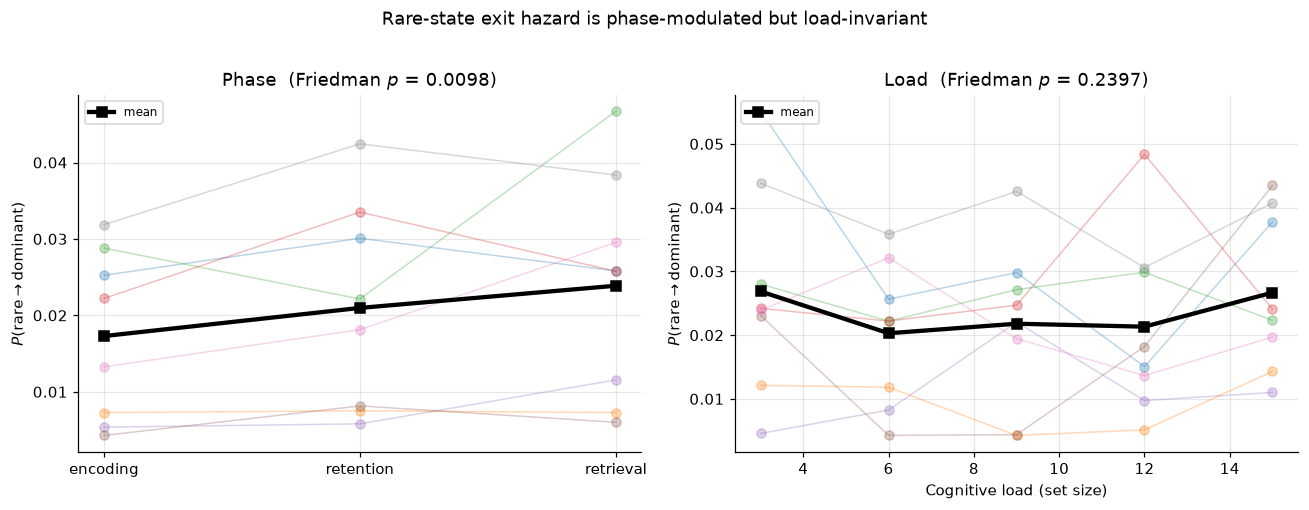

In [14]:
# --- Two-panel: rare-state exit hazard by phase and by load ---

def accumulate_transitions_by_load(trial_data, subject):
    """Per-load 2x2 transition count matrix for one subject."""
    counts = {}
    for r in trial_data:
        if r["subject"] != subject:
            continue
        load = r["load"]
        if load not in counts:
            counts[load] = np.zeros((2, 2), dtype=int)
        v = r["viterbi"]
        for i in range(1, len(v)):
            counts[load][v[i - 1], v[i]] += 1
    return counts


load_rd_rows = []
for sub in config.DEV_SUBJECTS:
    c_by_load = accumulate_transitions_by_load(all_trial_data, sub)
    for load, c in c_by_load.items():
        n_rare = int(c[1].sum())
        if n_rare > 0:
            load_rd_rows.append({
                "subject": sub,
                "load": int(load),
                "P_rare_to_dom": c[1, 0] / n_rare,
                "n_rare": n_rare,
            })
pivot_rd_load = pd.DataFrame(load_rd_rows).pivot(
    index="subject", columns="load", values="P_rare_to_dom"
).dropna(axis=1)
loads_rd = sorted(pivot_rd_load.columns)

# Friedman across loads for the record
stat_load, p_load = stats.friedmanchisquare(
    *[pivot_rd_load[l].values for l in loads_rd]
)
print(f"Friedman P(rare->dom) across loads: chi2={stat_load:.3f}, p={p_load:.4f}")
print(pivot_rd_load.round(4).to_string())
print()

# Friedman across phases for the phase panel title
stat_phase, p_phase = stats.friedmanchisquare(
    *[pivot_rd[ph].values for ph in phases]
)

# --- Plot ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: phase
ax = axes[0]
for sub in pivot_rd.index:
    ax.plot(phases, pivot_rd.loc[sub, phases].values,
            marker="o", alpha=0.30, linewidth=1)
ax.plot(phases, pivot_rd[phases].mean().values,
        marker="s", linewidth=2.8, color="black", label="mean")
ax.set_ylabel(r"$P(\mathrm{rare} \to \mathrm{dominant})$")
ax.set_title(f"Phase  (Friedman $p$ = {p_phase:.4f})")
ax.legend(fontsize=8, loc="upper left")
ax.grid(alpha=0.3)

# Right: load
ax = axes[1]
for sub in pivot_rd_load.index:
    ax.plot(loads_rd, pivot_rd_load.loc[sub, loads_rd].values,
            marker="o", alpha=0.30, linewidth=1)
ax.plot(loads_rd, pivot_rd_load[loads_rd].mean().values,
        marker="s", linewidth=2.8, color="black", label="mean")
ax.set_xlabel("Cognitive load (set size)")
ax.set_ylabel(r"$P(\mathrm{rare} \to \mathrm{dominant})$")
ax.set_title(f"Load  (Friedman $p$ = {p_load:.4f})")
ax.legend(fontsize=8, loc="upper left")
ax.grid(alpha=0.3)

fig.suptitle("Rare-state exit hazard is phase-modulated but load-invariant",
             y=1.02, fontsize=12)
plt.tight_layout()

out_path = config.RESULTS / "figures" / "phase_vs_load_exit_hazard.png"
fig.savefig(out_path, dpi=150, bbox_inches="tight")
print(f"Saved -> {out_path}")
plt.show()

Saved -> D:\Research\eeg-neural-state-dynamics\results\figures\state_topographies.png


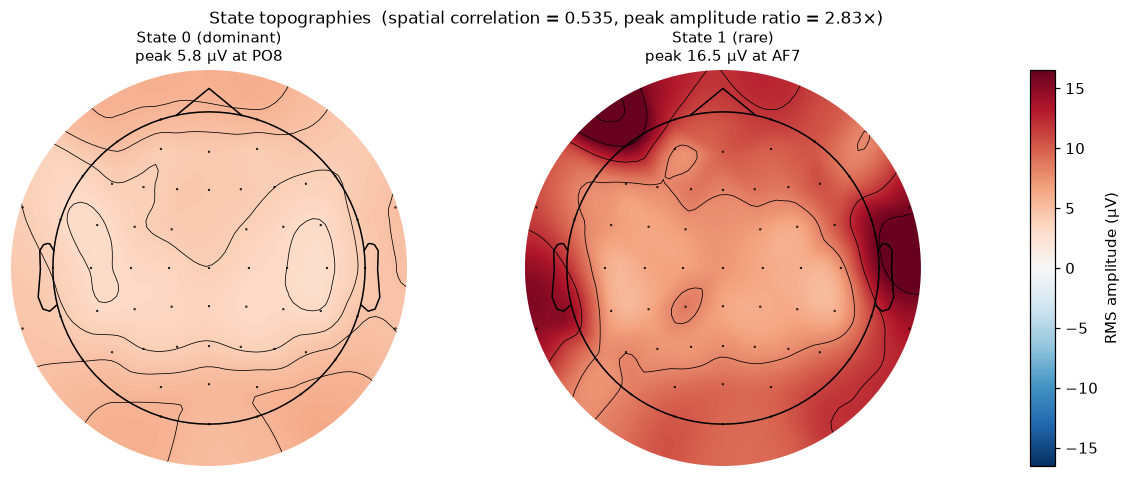

: 

In [ ]:
# --- Two-state topography figure for README ---

# Ensure topo and raw0 are in memory (from Part 1 topography cell)
assert 'topo' in globals() and 'raw0' in globals(), \
    "run the Part 1 topography cell first"

spatial_corr = np.corrcoef(topo[0], topo[1])[0, 1]
amp_ratio = np.abs(topo[1]).max() / np.abs(topo[0]).max()

fig = plt.figure(figsize=(11, 4.5))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.06],
                       left=0.05, right=0.92, bottom=0.08, top=0.88,
                       wspace=0.35)
ax0 = fig.add_subplot(gs[0])
ax1 = fig.add_subplot(gs[1])
cax = fig.add_subplot(gs[2])

vmax = np.abs(topo).max()
for k, ax in [(0, ax0), (1, ax1)]:
    im, _ = mne.viz.plot_topomap(
        topo[k], raw0.info, axes=ax, show=False,
        cmap="RdBu_r", vlim=(-vmax, vmax), contours=4,
    )
    label = "rare" if k == RARE_STATE else "dominant"
    peak_uv = np.abs(topo[k]).max()
    # Identify top channel for the subtitle
    top_ch = raw0.ch_names[int(np.argmax(np.abs(topo[k])))]
    ax.set_title(f"State {k} ({label})\npeak {peak_uv:.1f} µV at {top_ch}",
                 fontsize=10)

fig.colorbar(im, cax=cax, label="RMS amplitude (µV)")

fig.suptitle(
    f"State topographies  "
    f"(spatial correlation = {spatial_corr:.3f}, "
    f"peak amplitude ratio = {amp_ratio:.2f}×)",
    fontsize=11, y=1.00,
)

out_path = config.RESULTS / "figures" / "state_topographies.png"
fig.savefig(out_path, dpi=150, bbox_inches="tight")
print(f"Saved -> {out_path}")
plt.show()